1. Why is feature scaling essential prior to executing K-Means, DBSCAN, or HDBSCAN on the Wine dataset? Specifically, how would unscaled features distort distance calculations relative to other features? Provide specific examples.

It is essential because they rely on distance calculations to identify similar data points. Without scaling, features with larger numeric ranges dominate these calculations. For example, proline has a standard deviation of about 315, while alcohol is only 0.81. This causes proline to influence clustering much more than alcohol, regardless of its actual importance. For K-Means, clusters become heavily influenced by larger-valued features. DBSCAN struggles to find an appropriate eps value, while HDBSCAN inherits the same distance bias when identifying dense regions. Using StandardScaler gives all 13 features a mean of 0 and standard deviation of 1, allowing each feature to contribute more equally and producing clusters that better reflect overall chemical similarities.

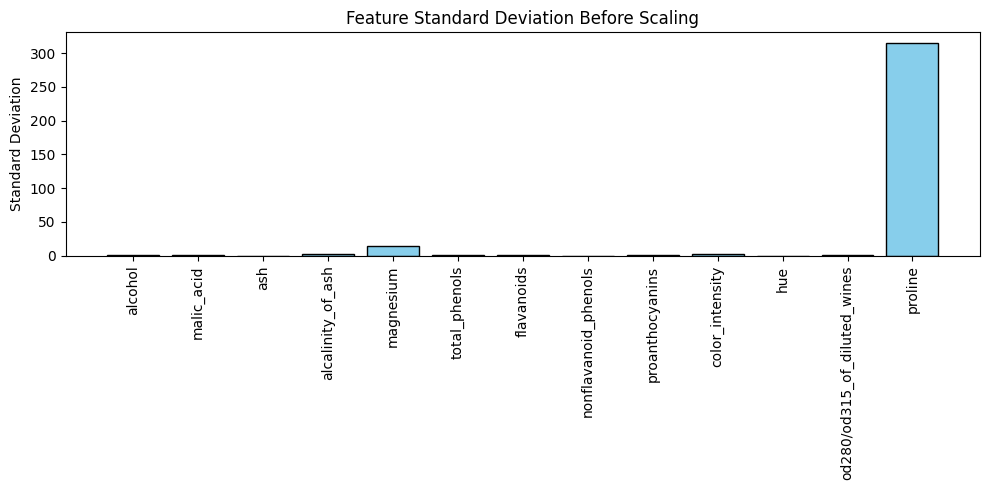

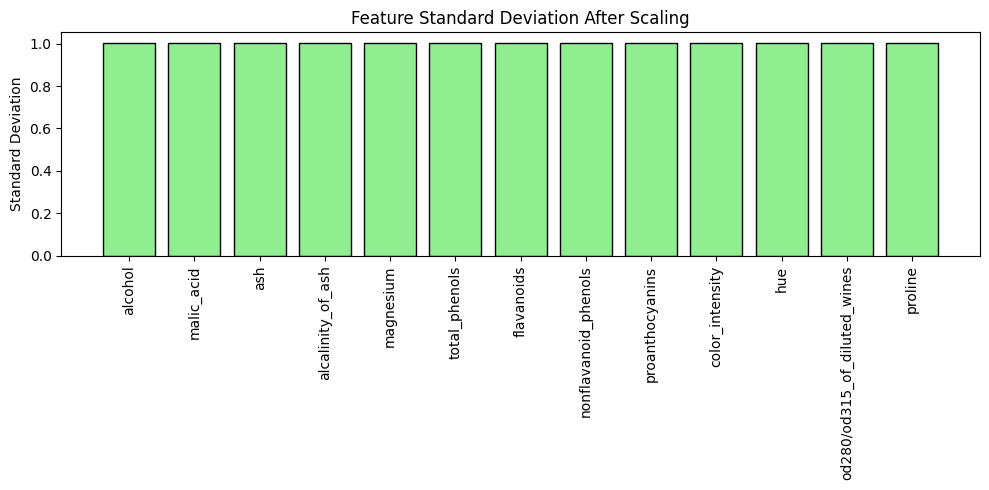

2. How did the Elbow Method and Silhouette Analysis in Task 2 reflect the natural structure of the Wine dataset? Did both evaluation metrics align with the true number of wine cultivars (k=3)? Explain any discrepancies observed.

Both the Elbow Method and Silhouette Analysis identified k=3 as the optimal number of clusters, matching the three actual wine cultivars. Inertia decreased significantly up to k=3 before leveling off, while the Silhouette Score peaked at 0.2849. This was further supported by Task 8, where K-Means achieved 97.2% accuracy in predicting the true cultivars. However, the elbow was gradual rather than clearly defined. The relatively low Silhouette Score suggests some overlap between clusters, and k=2 produced a similar result. Although both methods agreed on k=3, they only measure cluster separation and cannot confirm the actual wine classes. The high accuracy in Task 8 provides stronger evidence that the clusters represent the true cultivars.

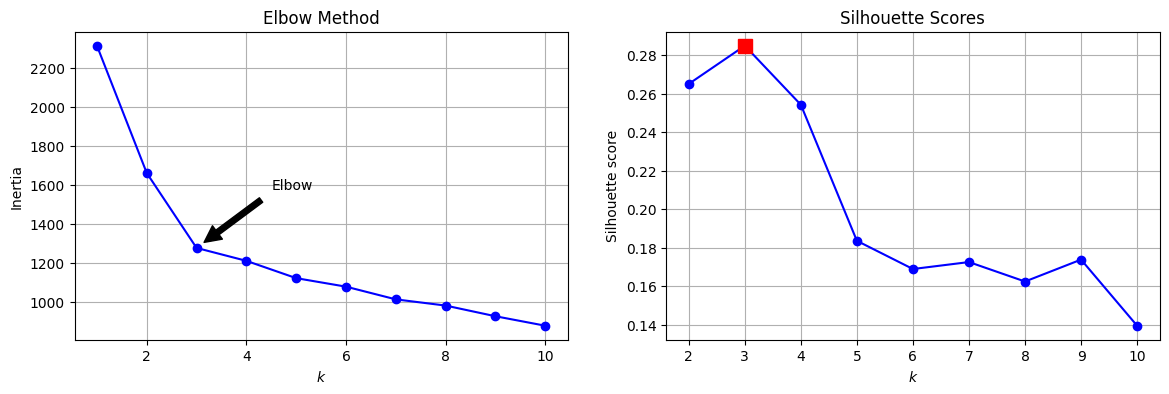

3. Compare the clustering behavior and cluster assignments of K-Means against DBSCAN and HDBSCAN on the 13-dimensional Wine feature space. Why did DBSCAN and HDBSCAN classify specific wine samples as noise, while K-Means assigned every sample to a cluster?


K-Means assigned all 178 wines to 3 clusters with no outliers, achieving 97.2% accuracy. DBSCAN identified 3 clusters with 32 noise points (72.2% accuracy), while HDBSCAN identified 2 clusters with 58 noise points (75.0% accuracy). Both density-based methods struggled to separate cultivars 0 and 1. DBSCAN and HDBSCAN label points as noise when they lack enough nearby neighbors to form dense clusters. This is especially challenging with 13 features and only 178 samples, since high-dimensional data makes identifying dense regions more difficult. Most noise points came from cultivar 1, which had greater variation in chemical characteristics. Though HDBSCAN had a higher Silhouette Score (0.352) than K-Means (0.285), it excluded noise points from its evaluation, making the comparison less direct. Overall, K-Means performed best because it successfully grouped all wines and better matched the actual cultivars.

4. Contrast the operational mechanisms of standard DBSCAN and HDBSCAN. How does HDBSCAN's hierarchical, stability-based approach overcome DBSCAN's vulnerability to a single global eps parameter when clustering chemical datasets with varying local densities?

DBSCAN uses a fixed neighborhood radius (eps) and minimum density requirement (min_samples) to form clusters. Points that lack enough nearby neighbors are labeled as noise. Because eps applies to the entire dataset, DBSCAN struggles when clusters have different densities. In Task 5, changing the parameters produced anywhere from 1 to 8 clusters and 7 to 178 noise points. Using eps = 2.3 and min_samples = 3 resulted in 3 clusters and 32 noise points.

HDBSCAN improves on DBSCAN by analyzing multiple density levels instead of relying on a single eps. It builds a hierarchy of clusters and selects those that remain stable across different density thresholds. This allows it to identify clusters with varying densities. However, it still depends on parameters like min_cluster_size and min_samples.

In my results, HDBSCAN identified 2 clusters with 58 noise points and achieved 75.0% accuracy, compared to DBSCAN's 72.2% and K-Means' 97.2%. Although HDBSCAN handles varying densities more flexibly, it labeled about a third of the wines as noise. Overall, HDBSCAN reduces the need for manual eps tuning but does not guarantee better clustering, especially with small, high-dimensional datasets.

5. Based on your comparative classification experiment in Task 8, how effectively did the cluster assignments from K-Means, DBSCAN, and HDBSCAN enable a downstream classifier to predict the true ground-truth wine cultivars (Class 0-2)? Discuss the limitations of mapping unsupervised clusters to supervised class labels when dealing with noise and density-based groupings.


K-Means cluster labels were the most effective at predicting the actual wine cultivars. I was able to get 97.2% accuracy with Random Forest, DBSCAN achieved 72.2%, and HDBSCAN reached 75.0%. This shows that K-Means clusters aligned much more closely with the true wine classes. One limitation is that the classifier only sees cluster labels, so it cannot distinguish cultivars grouped into the same cluster. K-Means benefited from being assigned exactly 3 clusters, while HDBSCAN identified only 2. Additionally, DBSCAN labeled 32 wines as noise and HDBSCAN labeled 58, grouping different wines into a single noise category that provides limited predictive information. HDBSCAN had the highest Silhouette Score (0.352), but it had much lower classification accuracy because noise points were excluded from its silhouette calculation. Overall, higher Silhouette Scores do not necessarily mean better classification accuracy, since well-separated clusters do not always match the actual classes. Cluster labels are also arbitrary, and the small test set makes minor accuracy differences less reliable.


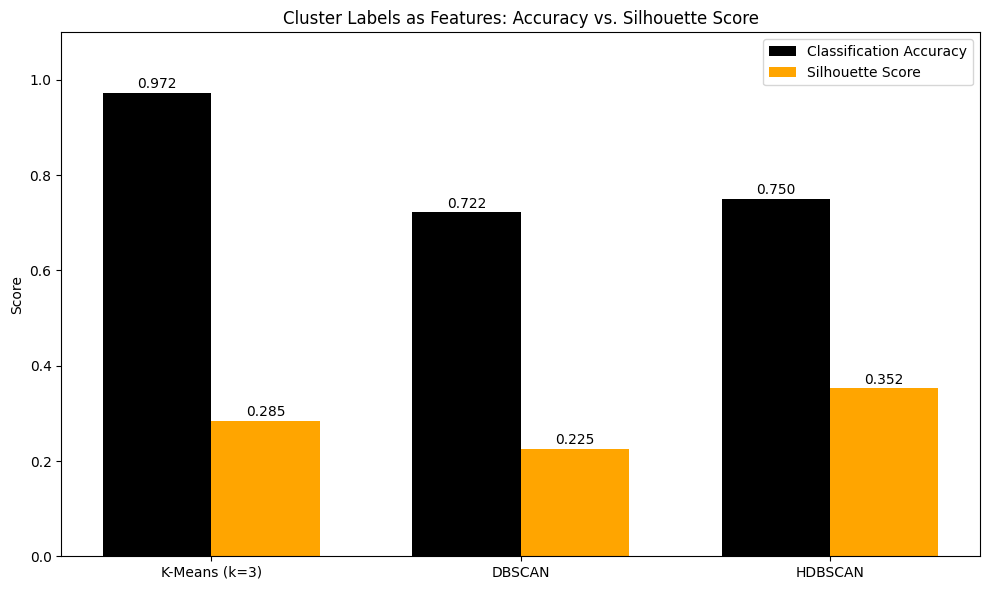